# QE018: Ghost Particles in the Ice

**A neutrino's journey: born in a cosmic accelerator, oscillating across the universe, crossing the Earth, and caught
by a cubic kilometre of Antarctic ice.**

Neutrinos are almost massless, electrically neutral, and so weakly interacting that trillions pass through you every
second unnoticed. That makes them perfect messengers: they escape from the densest places in the universe and travel
in straight lines. It also makes them nearly impossible to catch. IceCube solves this with sheer size: 5,160 light
sensors frozen into a cubic kilometre of ice under the South Pole, watching for the faint blue flashes of the rare
neutrinos that do interact.

On the way, neutrinos perform one of the most striking quantum effects in nature: they **oscillate**. A neutrino
created as one "flavour" travels as a superposition of three mass states, and the flavour you detect depends on the
distance travelled and the energy. This exercise follows that journey:

* **Part A (one exact answer, Euler-style):** the flavour mix that arrives at Earth from a cosmic accelerator.
* **Part B1:** the flavour triangle, and what it reveals about the source.
* **Part B2:** neutrinos crossing the Earth: oscillations and the effect of matter.
* **Part B3:** catching them: Cherenkov light in ice, and reconstructing a neutrino's direction.
* **Part B4:** the Glashow resonance, where a neutrino and an electron create a W boson.
* **Animation:** an IceCube-style event display of a muon crossing the detector.

### Words used in this notebook

| term | meaning |
|---|---|
| **flavour (e, μ, τ)** | the three kinds of neutrino, named after the charged particle they produce: electron, muon, tau |
| **mass states (1, 2, 3)** | the three states with definite mass; each flavour is a quantum superposition of them |
| **PMNS matrix U** | the 3×3 table of amplitudes linking flavours and mass states, set by three mixing angles θ₁₂, θ₂₃, θ₁₃ and a phase δ |
| **oscillation** | the flavour changing with distance, because the mass states run at slightly different speeds |
| **Δm²** | difference of squared masses; it sets the oscillation length, $L_\text{osc} \propto E/\Delta m^2$ |
| **flavour ratio** | the fractions $f_e : f_\mu : f_\tau$ of the three flavours |
| **pion decay** | the main neutrino factory in cosmic accelerators: $\pi^+ \to \mu^+\nu_\mu$, then $\mu^+ \to e^+\nu_e\bar\nu_\mu$, giving flavours 1 : 2 : 0 |
| **matter effect (MSW)** | electrons in matter push only on $\nu_e$, changing oscillations inside the Earth |
| **atmospheric neutrinos** | neutrinos made by cosmic rays hitting the atmosphere; IceCube measures oscillations with those crossing the Earth |
| **Cherenkov light** | the blue light emitted when a charged particle moves faster than light does in the ice |
| **DOM** | digital optical module: one of IceCube's light sensors, hung on vertical cables called strings |
| **track / cascade** | the two event shapes: a long muon track, or a compact ball of light from an electron or tau shower |
| **reconstruction** | inferring the neutrino's direction and energy from which sensors lit up, and when |
| **Glashow resonance** | an antineutrino of exactly the right energy meets an electron and creates a W boson |
| **random seed** | fixes the random draws so every run gives the same numbers |

*Report version: the code is hidden; figures, tables and the animation are the results of the full computation.*

## 1. Three flavours, three masses

A neutrino born as flavour $\alpha$ is the superposition $|\nu_\alpha\rangle = \sum_i U^\ast_{\alpha i}|\nu_i\rangle$ of
mass states. Each mass state picks up a phase $e^{-i m_i^2 L / 2E}$ as it travels. After a distance $L$ the probability
of detecting flavour $\beta$ is

$$P_{\alpha\to\beta}(L, E) = \Big|\sum_i U_{\beta i}\,U^\ast_{\alpha i}\,e^{-i m_i^2 L/2E}\Big|^2 .$$

We use the current global fit of all oscillation experiments, **NuFIT 6.0** (normal mass ordering, without
Super-Kamiokande atmospheric data):
$\theta_{12} = 33.68°$, $\theta_{23} = 48.5°$, $\theta_{13} = 8.52°$, $\delta = 177°$,
$\Delta m^2_{21} = 7.49\times10^{-5}\,\text{eV}^2$, $\Delta m^2_{31} = 2.534\times10^{-3}\,\text{eV}^2$.

U is unitary: True
|U|^2 (rows e, mu, tau; columns mass states 1, 2, 3):
[[0.6773 0.3008 0.0219]
 [0.0758 0.3756 0.5486]
 [0.2469 0.3236 0.4294]]


## Part A: what flavour arrives from the cosmos?

Over cosmic distances (millions of light years) the oscillation phases cycle billions of times. A real detector
cannot resolve them, and the energy spread of the neutrinos smears them out completely. Only the *average* survives:

$$\bar P_{\alpha\to\beta} = \sum_{i} |U_{\alpha i}|^2\,|U_{\beta i}|^2 .$$

**Task:** a cosmic accelerator makes neutrinos by pion decay, with flavour ratio $1 : 2 : 0$ at the source. Using the
NuFIT 6.0 parameters above, compute the electron-neutrino fraction $f_e$ that arrives at Earth, and report

$$A = \lfloor 10^6 f_e \rfloor .$$

*Check value:* with idealised "tribimaximal" mixing ($\sin^2\theta_{12} = \tfrac13$, $\theta_{23} = 45°$,
$\theta_{13} = 0$), a $1:2:0$ source arrives as exactly $\tfrac13 : \tfrac13 : \tfrac13$.

check, tribimaximal mixing: [0.33333333 0.33333333 0.33333333]
NuFIT 6.0: f_e : f_mu : f_tau = 0.300775 : 0.357313 : 0.341912

ANSWER  A = 300775


The quantum mixing nearly equalises the three flavours: an accelerator that makes no tau neutrinos at all still
delivers about a third of them to Earth. IceCube's measurement of the flavour mix of astrophysical neutrinos (best fit
about $0.30 : 0.37 : 0.33$) agrees with this pion-decay picture.

## Part B1: the flavour triangle

Different production mechanisms give different source ratios:

| source | mechanism | ratio at source |
|---|---|---|
| **pion decay** | full chain $\pi \to \mu \to e$ | 1 : 2 : 0 |
| **muon-damped** | muons lose energy in strong magnetic fields before decaying | 0 : 1 : 0 |
| **neutron decay** | $n \to p\,e\,\bar\nu_e$ | 1 : 0 : 0 |

Each lands somewhere different at Earth. The mixing parameters are not known exactly, so we draw 3,000 random sets
from their measured uncertainties and plot where each source can land on the **flavour triangle** (every point is a
ratio that adds up to 1).

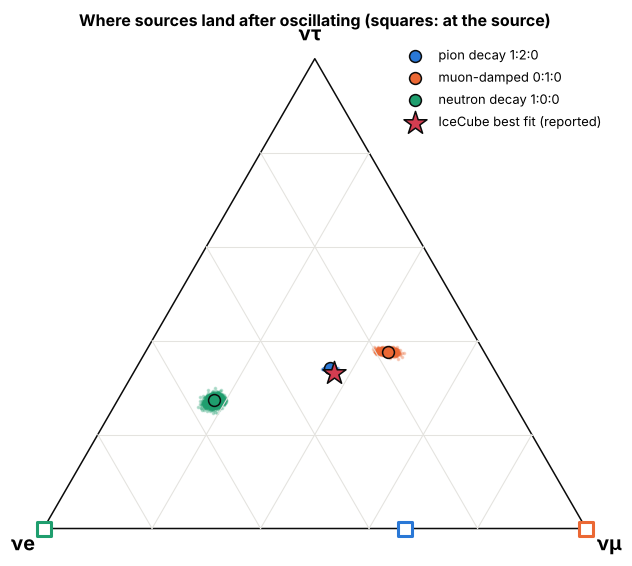

,f_e at Earth,f_mu,f_tau,spread of f_e (1σ)
source,,,,
pion decay 1:2:0,0.302,0.356,0.342,0.004
muon-damped 0:1:0,0.177,0.446,0.377,0.007
neutron decay 1:0:0,0.550,0.177,0.272,0.009


Oscillations squeeze every source towards the centre of the triangle, but not all the way: the three sources stay
distinguishable. That is why measuring the flavour mix of cosmic neutrinos tells us *how* they were made. A pure
neutron-decay source lands far from IceCube's measurement.

## Part B2: crossing the Earth

IceCube also studies **atmospheric neutrinos**, made when cosmic rays hit the atmosphere. Those arriving from below
have crossed the Earth: up to 12,700 km, with a dense iron core in the middle. Two things change compared with empty
space:

* the distance is short enough (and the energies low enough) that the oscillations are **not** averaged, so we see
  them directly;
* electrons in the Earth push on electron neutrinos only, adding $V = \sqrt2\,G_F N_e$ to their energy (the **MSW
  matter effect**).

We model the Earth as a mantle (4.6 g/cm³) and a core (11.3 g/cm³, radius 3,480 km). In each layer the Hamiltonian is
constant, $H = \frac{1}{2E}U\,\mathrm{diag}(0, \Delta m^2_{21}, \Delta m^2_{31})\,U^\dagger + \mathrm{diag}(V, 0, 0)$,
so the evolution is an exact matrix exponential, multiplied layer by layer along the path.

vacuum check: layered code 0.0381425488, formula 0.0381425488
first oscillation minimum, straight through the Earth: P(νμ→νμ) at 25 GeV = 0.015


oscillogram computed in 1 s


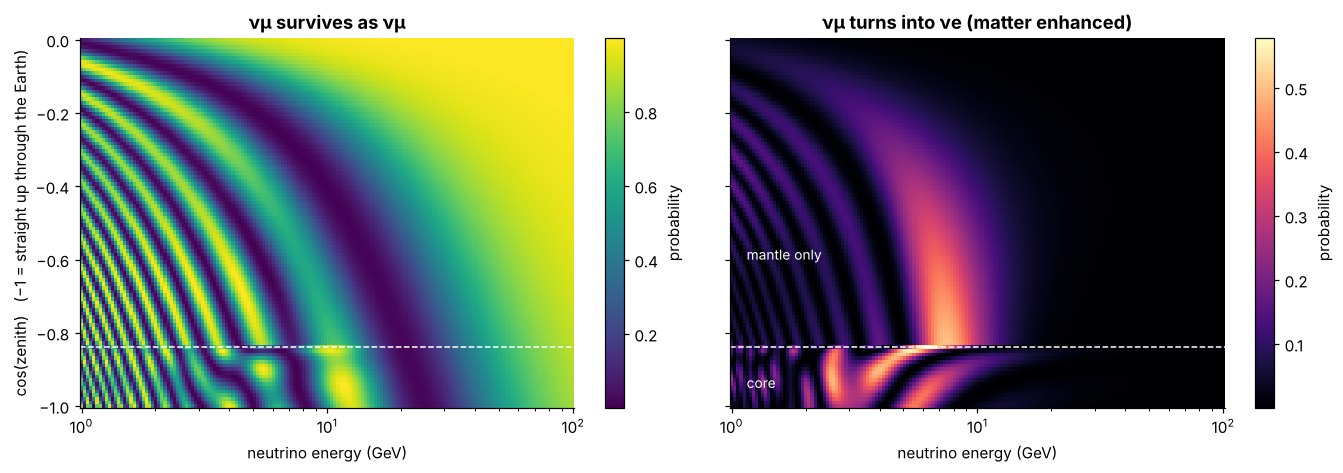

**Left:** muon neutrinos coming straight up through the Earth almost completely disappear near 25 GeV. This is the
first oscillation minimum, which IceCube's dense inner array DeepCore measures to pin down $\Delta m^2_{31}$ and
$\theta_{23}$. **Right:** in empty space, at most about 5% of muon neutrinos could turn into electron neutrinos here. Between
roughly 3 and 8 GeV the electrons of the mantle drive a resonant conversion of up to about half of them, and paths that
cross the core (below the dashed line) show an extra pattern of their own. That is a direct imprint of the Earth's
interior on a quantum effect.

## Part B3: catching a neutrino in the ice

When a muon neutrino interacts in or near the ice it creates a muon that flies for kilometres, faster than light travels
in ice. It emits **Cherenkov light** on a cone at angle $\theta_c = \arccos(1/n) \approx 41°$ ($n = 1.32$). A sensor at
distance $d$ from the track would see the first direct light at

$$t_\text{geo} = t_0 + \frac{\ell + d\tan\theta_c}{c},$$

with $\ell$ the distance along the track. But Antarctic ice scatters light. Photons arrive *later* than $t_\text{geo}$,
by a delay that grows with distance. A classic description (the **Pandel function**, used by IceCube's predecessor
AMANDA) treats the delay as Gamma-distributed with shape $d/\lambda$; we use its published parameters
$\tau = 557$ ns, $\lambda = 33.3$ m, absorption length 98 m.

**Toy detector:** 91 strings on a hexagonal grid with 125 m spacing, 60 sensors each spaced 17 m apart, covering
1 km vertically (IceCube itself has 86 strings and 5,160 sensors). **Toy light yield:** the expected light at each sensor
falls with distance and grows with muon energy. It is not IceCube's calibrated model, but it gives realistic numbers
of lit sensors.

**Reconstruction**, two ways:
1. **line fit:** treat hit times and positions as a point moving in a straight line, a quick least-squares estimate;
2. **likelihood fit:** find the track that makes the observed delays most probable under the Pandel model.

toy detector: 91 strings, 5460 sensors


simulated and reconstructed 75 muons in 18 s


,median lit sensors,line fit: median error (°),likelihood: median error (°)
muon energy (TeV),,,
1.0,94,2.26,0.43
10.0,276,1.91,0.41
100.0,625,2.34,0.30


The line fit ignores the physics of light in ice and is off by about two degrees. Using the Cherenkov geometry and the
scattering-delay model brings the error down several-fold, to a fraction of a degree. This is why IceCube can point
back to sources such as the galaxy NGC 1068 or the blazar TXS 0506+056. (Our toy has no ice layers, dust or
detector noise, so its numbers are optimistic.)

## Part B4: the Glashow resonance

In 1960 Sheldon Glashow noticed that an electron antineutrino hitting an electron at rest can produce a real W boson,
$\bar\nu_e + e^- \to W^-$, if the collision energy equals the W mass. With the electron at rest, $s = 2 m_e E_\nu$, so
the resonance sits at

$$E_\text{res} = \frac{m_W^2}{2 m_e}.$$

The cross-section follows a Breit–Wigner peak of width set by the W's decay width $\Gamma_W = 2.085$ GeV.

Glashow resonance energy: 6.320 PeV  (6.32e+06 GeV)


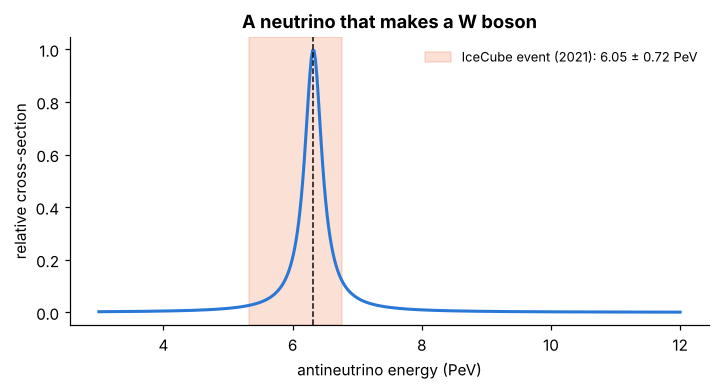

The resonance is extremely sharp: a few percent wide around 6.3 PeV. In 2021 IceCube reported a particle shower with
visible energy consistent with this resonance, the first sighting of the Glashow resonance, and evidence that the
cosmic flux contains electron *anti*neutrinos.

## Animation: an event in the ice

A 10 TeV muon (from a muon neutrino that crossed the Earth) passes through the toy detector. Sensors light up as the
Cherenkov cone sweeps past them, coloured by arrival time (red early, blue late, as in IceCube's own event displays)
and sized by how much light they saw. The view rotates slowly.

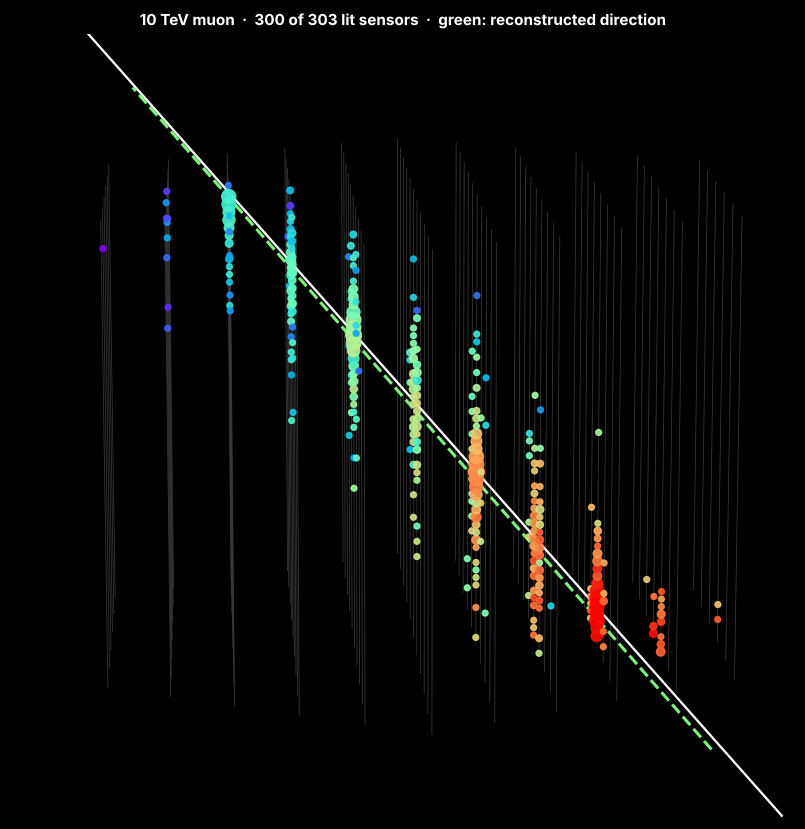

saved qe018_icecube_event.gif (22 s): 303 lit sensors, reconstruction error 0.63°


**The animation** (embedded, so it plays on GitHub without running anything):

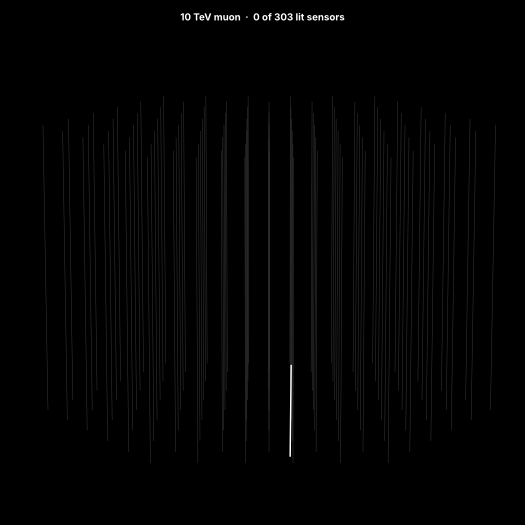

## Conclusions

1. **Exact answer.** A pion-decay source (1 : 2 : 0) arrives at Earth as
   $0.301 : 0.357 : 0.342$ with the NuFIT 6.0 mixing parameters, so $A = 300775$. Quantum mixing makes tau neutrinos
   from a source that produces none.
2. **Flavour is a fingerprint.** Different production mechanisms land in different parts of the flavour triangle, and
   IceCube's measurement favours pion decay.
3. **The Earth is part of the experiment.** Upward-going muon neutrinos vanish near 25 GeV, and the core's electrons
   resonantly convert some into electron neutrinos at a few GeV.
4. **Light in ice carries the direction.** Using the Cherenkov geometry and the physics of scattering turns a few
   degrees of error into a fraction of a degree, enough to do astronomy.
5. **Particle physics at the PeV frontier.** The Glashow resonance at $m_W^2/2m_e = 6.32$ PeV is a W-boson factory
   powered by cosmic antineutrinos.

**Try it yourself:** add the inverted mass ordering and compare the oscillograms, include antineutrinos (the matter
effect flips sign), simulate cascades (a point-like flash) and see how much worse their direction is, or vary the
scattering length to mimic dusty ice layers.

### Further reading

* IceCube Collaboration, *Evidence for high-energy extraterrestrial neutrinos at the IceCube detector*, Science 342,
  1242856 (2013).
* IceCube Collaboration, *Evidence for neutrino emission from the nearby active galaxy NGC 1068*, Science 378, 538
  (2022).
* IceCube Collaboration, *Observation of high-energy neutrinos from the Galactic plane*, Science 380, 1338 (2023).
* IceCube Collaboration, *Detection of a particle shower at the Glashow resonance with IceCube*, Nature 591, 220 (2021).
* F. Halzen, S. R. Klein, *IceCube: an instrument for neutrino astronomy*, Rev. Sci. Instrum. 81, 081101 (2010).
* I. Esteban et al., *NuFit-6.0: updated global analysis of three-flavor neutrino oscillations*, JHEP 12, 216 (2024).
* AMANDA Collaboration (J. Ahrens et al.), *Muon track reconstruction and data selection techniques in AMANDA*,
  Nucl. Instrum. Meth. A 524, 169 (2004).